# Escenarios 2027: sin y con intervención

**Objetivo.** Comparar, para cada **municipio**, la abstención pronosticada para 2027 **sin intervención** (el pronóstico de `pronostico_2027.ipynb`) contra una **intervención hipotética** que baja la abstención de 1 a 5 puntos porcentuales. Se mide cuántos municipios cambian de color en el semáforo y cuántas personas más votarían.

**Datos.** Solo se lee `Datos/datos_procesados/modelo/pronostico_2027.csv`. No se entrena ningún modelo nuevo: la intervención es un **supuesto**, porque los datos no contienen ninguna campaña real.

**Decisiones de diseño.**
- El efecto es **el mismo para todos los municipios** (puntos fijos: 1, 2, 3, 4 y 5). El 0 es el escenario sin intervención.
- Cualquier municipio puede recibir la intervención; el tablero permite elegir cuáles. Aquí se calcula el efecto para todos y el filtro se aplica en el mapa.
- Los **umbrales del semáforo** son los del escenario sin intervención (terciles del pronóstico). Se mantienen fijos en los escenarios con intervención; si se recalcularan, siempre saldría un tercio de cada color y no se vería ningún cambio.
- No hay piso: la abstención solo se limita a no ser negativa.
- Los 12 municipios sin pronóstico quedan fuera (sin datos suficientes). Los 20 de confianza baja se conservan con la marca `PRELIMINAR`.

**Prioridad.** `ABSTENCIONISTAS_ESP` = personas de 2024 × abstención pronosticada. Es cuánta gente hay que convencer en el municipio; combina riesgo y tamaño.

**Qué se guarda.** `escenarios_2027.csv` (un renglón por municipio, con todos los efectos) . Las columnas se describen en `Datos/datos_procesados/modelo/diccionario.txt`. Ambos alimentan el mapa y el reporte.

## 1. Configuración y lectura
Se define dónde está el pronóstico y dónde se guardarán los resultados, los efectos a probar (en puntos porcentuales) y se lee el archivo.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_cwd = Path.cwd().resolve()
RAIZ = next(p for p in [_cwd, *_cwd.parents] if (p / "Datos").is_dir())
CARPETA = RAIZ / "Datos" / "datos_procesados" / "modelo"
RUTA_PRONOSTICO = CARPETA / "pronostico_2027.csv"
RUTA_SALIDA = CARPETA / "escenarios_2027.csv"

EFECTOS = [1, 2, 3, 4, 5]

pron = pd.read_csv(RUTA_PRONOSTICO, encoding="utf-8-sig")
print(f"{len(pron):,} municipios | {pron['PRON_2027_BOOSTING'].notna().sum():,} con pronóstico")
pron.head()

2,475 municipios | 2,463 con pronóstico


,ESTADO,MUNICIPIO,ELECCIONES,PERSONAS_2024,ABST_2024,PRON_2027_BOOSTING,PRON_2027_LOGISTICA,CAMBIO_VS_2024,SEMAFORO,CONFIANZA
0,AGUASCALIENTES,AGUASCALIENTES,6,712266.0,0.4192,0.5516,0.5411,0.1324,Rojo,Alta
1,AGUASCALIENTES,ASIENTOS,6,38773.0,0.3572,0.4588,0.4820,0.1015,Amarillo,Alta
2,AGUASCALIENTES,CALVILLO,6,48968.0,0.4816,0.5762,0.5827,0.0946,Rojo,Alta
3,AGUASCALIENTES,COSIO,6,12824.0,0.2778,0.3859,0.4230,0.1081,Verde,Alta
4,AGUASCALIENTES,EL LLANO,6,16325.0,0.3230,0.4199,0.4533,0.0969,Verde,Alta


## 2. Escenario sin intervención y umbrales del semáforo
Se toma el pronóstico de boosting como abstención **sin intervención** (`PRON_SIN`) y su semáforo tal como está en `pronostico_2027.csv`. Los umbrales son el pronóstico más alto de los municipios verdes y el más alto de los amarillos (los terciles del pronóstico); con ellos se asignará el color en los escenarios con intervención.

In [11]:
UMBRAL_VERDE = pron.loc[pron["SEMAFORO"] == "Verde", "PRON_2027_BOOSTING"].max()
UMBRAL_ROJO = pron.loc[pron["SEMAFORO"] == "Amarillo", "PRON_2027_BOOSTING"].max()
print(f"Verde hasta {UMBRAL_VERDE:.2%} | Amarillo hasta {UMBRAL_ROJO:.2%} | Rojo por encima")

esc = pron[["ESTADO", "MUNICIPIO", "ELECCIONES", "CONFIANZA", "PERSONAS_2024"]].copy()
esc["PRON_SIN"] = pron["PRON_2027_BOOSTING"]
esc["SEMAFORO_SIN"] = pron["SEMAFORO"]
esc["SEMAFORO_SIN"].value_counts()

Verde hasta 44.05% | Amarillo hasta 52.66% | Rojo por encima


SEMAFORO_SIN
Rojo                     821
Amarillo                 821
Verde                    821
Sin datos suficientes     12
Name: count, dtype: int64

## 3. Prioridad y marca de confianza
- `ABSTENCIONISTAS_ESP`: personas de 2024 × abstención pronosticada (cuántas personas no votarían).
- `PRIORIDAD`: lugar del municipio al ordenar por `ABSTENCIONISTAS_ESP` de mayor a menor (1 = el que más gente tiene por convencer).
- `PRELIMINAR`: "Sí" si el pronóstico tiene confianza baja (1 a 4 elecciones con 2024).

In [12]:
esc["ABSTENCIONISTAS_ESP"] = (esc["PERSONAS_2024"] * esc["PRON_SIN"]).round(0)
esc["PRIORIDAD"] = esc["ABSTENCIONISTAS_ESP"].rank(ascending=False, method="first").astype("Int64")
esc["PRELIMINAR"] = np.where(esc["CONFIANZA"] == "Baja", "Sí", "No")
esc.sort_values("PRIORIDAD").head()

,ESTADO,MUNICIPIO,ELECCIONES,CONFIANZA,PERSONAS_2024,PRON_SIN,SEMAFORO_SIN,ABSTENCIONISTAS_ESP,PRIORIDAD,PRELIMINAR
17,BAJA CALIFORNIA,TIJUANA,6,Alta,1542715.0,0.6272,Rojo,967591.0,1,No
235,CIUDAD DE MEXICO,IZTAPALAPA,6,Alta,1470958.0,0.4900,Amarillo,720769.0,2,No
1698,PUEBLA,PUEBLA,6,Alta,1285745.0,0.5408,Rojo,695331.0,3,No
195,CHIHUAHUA,JUAREZ,6,Alta,1095422.0,0.6163,Rojo,675109.0,4,No
347,GUANAJUATO,LEON,6,Alta,1237769.0,0.5346,Rojo,661711.0,5,No


## 4. Escenarios con intervención
Para cada efecto de 1 a 5 puntos se calcula, para **todos** los municipios con pronóstico:
- `PRON_CON_x`: la abstención sin intervención menos x puntos (sin bajar de 0).
- `SEMAFORO_CON_x`: el color con esa abstención y los **mismos umbrales** del escenario sin intervención.
- `PERSONAS_ADIC_x`: personas más que votarían = personas de 2024 × los puntos que bajó la abstención. Es una **consecuencia aritmética del supuesto**, no un resultado del modelo.

In [13]:
for e in EFECTOS:
    esc[f"PRON_CON_{e}"] = (esc["PRON_SIN"] - e / 100).clip(lower=0)
    esc[f"SEMAFORO_CON_{e}"] = np.select([esc[f"PRON_CON_{e}"] <= UMBRAL_VERDE, esc[f"PRON_CON_{e}"] <= UMBRAL_ROJO],
                                         ["Verde", "Amarillo"], default="Rojo")
    esc.loc[esc["PRON_SIN"].isna(), f"SEMAFORO_CON_{e}"] = "Sin datos suficientes"
    esc[f"PERSONAS_ADIC_{e}"] = (esc["PERSONAS_2024"] * (esc["PRON_SIN"] - esc[f"PRON_CON_{e}"])).round(0)

print(f"{esc.shape[0]:,} municipios | {esc.shape[1]} columnas")
esc.head()

2,475 municipios | 25 columnas


,ESTADO,MUNICIPIO,ELECCIONES,CONFIANZA,PERSONAS_2024,PRON_SIN,SEMAFORO_SIN,ABSTENCIONISTAS_ESP,PRIORIDAD,PRELIMINAR,...,PERSONAS_ADIC_2,PRON_CON_3,SEMAFORO_CON_3,PERSONAS_ADIC_3,PRON_CON_4,SEMAFORO_CON_4,PERSONAS_ADIC_4,PRON_CON_5,SEMAFORO_CON_5,PERSONAS_ADIC_5
0,AGUASCALIENTES,AGUASCALIENTES,6,Alta,712266.0,0.5516,Rojo,392886.0,16,No,...,14245.0,0.5216,Amarillo,21368.0,0.5116,Amarillo,28491.0,0.5016,Amarillo,35613.0
1,AGUASCALIENTES,ASIENTOS,6,Alta,38773.0,0.4588,Amarillo,17789.0,451,No,...,775.0,0.4288,Verde,1163.0,0.4188,Verde,1551.0,0.4088,Verde,1939.0
2,AGUASCALIENTES,CALVILLO,6,Alta,48968.0,0.5762,Rojo,28215.0,316,No,...,979.0,0.5462,Rojo,1469.0,0.5362,Rojo,1959.0,0.5262,Amarillo,2448.0
3,AGUASCALIENTES,COSIO,6,Alta,12824.0,0.3859,Verde,4949.0,1156,No,...,256.0,0.3559,Verde,385.0,0.3459,Verde,513.0,0.3359,Verde,641.0
4,AGUASCALIENTES,EL LLANO,6,Alta,16325.0,0.4199,Verde,6855.0,932,No,...,327.0,0.3899,Verde,490.0,0.3799,Verde,653.0,0.3699,Verde,816.0


## 5. Resumen por efecto
Una fila por escenario (0 = sin intervención): cuántos municipios hay de cada color, cuántos cambian de color (y de cuál a cuál) y cuántas personas más votarían.

**Cómo leerlo.** Los cambios de color dependen de cuántos municipios están cerca de los umbrales (un municipio que pasa de 52.8 % a 52.6 % cambia de color igual que uno que baja 5 puntos), así que se leen como tendencia y junto con las personas adicionales.

In [14]:
filas = []
for e in [0] + EFECTOS:
    antes = esc["SEMAFORO_SIN"]
    despues = antes if e == 0 else esc[f"SEMAFORO_CON_{e}"]
    filas.append({
        "EFECTO_PUNTOS": e,
        "VERDES": (despues == "Verde").sum(),
        "AMARILLOS": (despues == "Amarillo").sum(),
        "ROJOS": (despues == "Rojo").sum(),
        "ROJO_A_AMARILLO": ((antes == "Rojo") & (despues == "Amarillo")).sum(),
        "AMARILLO_A_VERDE": ((antes == "Amarillo") & (despues == "Verde")).sum(),
        "CAMBIAN_DE_COLOR": (antes != despues).sum(),
        "PERSONAS_ADICIONALES": 0 if e == 0 else esc[f"PERSONAS_ADIC_{e}"].sum(),
    })
resumen = pd.DataFrame(filas)
resumen

,EFECTO_PUNTOS,VERDES,AMARILLOS,ROJOS,ROJO_A_AMARILLO,AMARILLO_A_VERDE,CAMBIAN_DE_COLOR,PERSONAS_ADICIONALES
0,0,821,821,821,0,0,0,0.0
1,1,905,837,721,100,84,184,920056.0
2,2,989,864,610,211,168,379,1840110.0
3,3,1066,892,505,316,245,561,2760142.0
4,4,1152,892,419,402,331,733,3680178.0
5,5,1259,872,332,489,438,927,4600184.0


## 6. Gráfica: municipios por color según el efecto
Barras apiladas con el número de municipios verdes, amarillos y rojos en cada escenario. Con más puntos de efecto, los rojos se reducen.

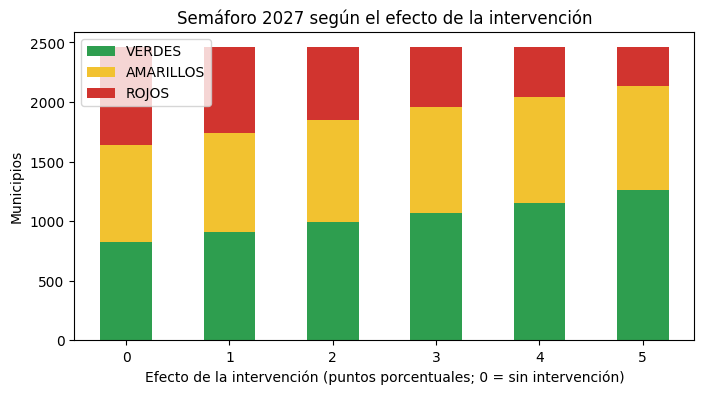

In [15]:
colores = {"VERDES": "#2e9e4f", "AMARILLOS": "#f2c230", "ROJOS": "#d1342f"}
ax = resumen.set_index("EFECTO_PUNTOS")[list(colores)].plot(kind="bar", stacked=True, color=list(colores.values()), figsize=(8, 4))
ax.set_xlabel("Efecto de la intervención (puntos porcentuales; 0 = sin intervención)")
ax.set_ylabel("Municipios")
ax.set_title("Semáforo 2027 según el efecto de la intervención")
plt.xticks(rotation=0)
plt.show()

## 7. Matriz de cambio de color (ejemplo con 3 puntos)
Filas: color sin intervención. Columnas: color con 3 puntos de efecto. Lo que está fuera de la diagonal son los municipios que cambian. Ningún municipio salta dos colores.

In [16]:
EFECTO_EJEMPLO = 3
pd.crosstab(esc["SEMAFORO_SIN"], esc[f"SEMAFORO_CON_{EFECTO_EJEMPLO}"], margins=True)

SEMAFORO_CON_3,Amarillo,Rojo,Sin datos suficientes,Verde,All
SEMAFORO_SIN,,,,,
Amarillo,576,0,0,245,821
Rojo,316,505,0,0,821
Sin datos suficientes,0,0,12,0,12
Verde,0,0,0,821,821
All,892,505,12,1066,2475


## 8. Municipios prioritarios
Los 15 municipios con más abstencionistas esperados. En el mapa, el rojo es más oscuro cuanto mayor es la abstención pronosticada; esta tabla ordena en cambio por cuánta gente hay que convencer.

In [17]:
esc.sort_values("PRIORIDAD").head(15)[["PRIORIDAD", "ESTADO", "MUNICIPIO", "PERSONAS_2024", "PRON_SIN",
                                       "SEMAFORO_SIN", "ABSTENCIONISTAS_ESP", "CONFIANZA"]]

,PRIORIDAD,ESTADO,MUNICIPIO,PERSONAS_2024,PRON_SIN,SEMAFORO_SIN,ABSTENCIONISTAS_ESP,CONFIANZA
17,1,BAJA CALIFORNIA,TIJUANA,1542715.0,0.6272,Rojo,967591.0,Alta
235,2,CIUDAD DE MEXICO,IZTAPALAPA,1470958.0,0.4900,Amarillo,720769.0,Alta
1698,3,PUEBLA,PUEBLA,1285745.0,0.5408,Rojo,695331.0,Alta
195,4,CHIHUAHUA,JUAREZ,1095422.0,0.6163,Rojo,675109.0,Alta
347,5,GUANAJUATO,LEON,1237769.0,0.5346,Rojo,661711.0,Alta
703,6,MEXICO,ECATEPEC DE MORELOS,1242761.0,0.5228,Amarillo,649715.0,Alta
584,7,JALISCO,GUADALAJARA,1215559.0,0.5276,Rojo,641329.0,Alta
664,8,JALISCO,ZAPOPAN,1060548.0,0.5411,Rojo,573863.0,Alta
1003,9,NUEVO LEON,MONTERREY,890306.0,0.5323,Rojo,473910.0,Alta
233,10,CIUDAD DE MEXICO,GUSTAVO A MADERO,1033871.0,0.4571,Amarillo,472582.0,Alta


## 9. Guardar los resultados y el diccionario
Se guarda `escenarios_2027.csv` y un diccionario que explica cada columna, para que cualquier persona pueda reproducir y leer el archivo. Si falta describir alguna columna, la celda se detiene con un error.

In [18]:
descripcion = {
    "ESTADO": "Estado del municipio.",
    "MUNICIPIO": "Nombre del municipio (se identifica junto con ESTADO).",
    "ELECCIONES": "Número de elecciones (de las 6, 2009-2024) en que el municipio tiene datos.",
    "CONFIANZA": "Respaldo del pronóstico: Alta (6 elecciones), Media (5 con 2024), Baja (1 a 4 con 2024) o Sin pronóstico (sin 2024).",
    "PERSONAS_2024": "Personas (votaron o no) del municipio en 2024; se usa como tamaño en 2027.",
    "PRON_SIN": "Abstención pronosticada para 2027 sin intervención (proporción de 0 a 1; gradient boosting).",
    "SEMAFORO_SIN": "Color sin intervención: Verde, Amarillo o Rojo (terciles del pronóstico) o Sin datos suficientes.",
    "ABSTENCIONISTAS_ESP": "Personas de 2024 por abstención pronosticada: personas que no votarían sin intervención.",
    "PRIORIDAD": "Lugar del municipio por ABSTENCIONISTAS_ESP, de mayor a menor (1 = más gente por convencer).",
    "PRELIMINAR": "Sí si la confianza es Baja (pronóstico preliminar); No en otro caso.",
}
for e in EFECTOS:
    descripcion[f"PRON_CON_{e}"] = f"Abstención pronosticada con una intervención hipotética que la baja {e} punto(s) porcentual(es); no baja de 0."
    descripcion[f"SEMAFORO_CON_{e}"] = f"Color con {e} punto(s) de efecto, con los mismos umbrales del escenario sin intervención."
    descripcion[f"PERSONAS_ADIC_{e}"] = f"Personas más que votarían con {e} punto(s) de efecto (personas de 2024 por los puntos que baja la abstención)."

diccionario = pd.DataFrame({"COLUMNA": esc.columns, "DESCRIPCION": [descripcion[c] for c in esc.columns]})

esc.to_csv(RUTA_SALIDA, index=False, encoding="utf-8-sig")
print(f"Guardado: {RUTA_SALIDA.name} ({esc.shape[0]:,} filas, {esc.shape[1]} columnas)")
diccionario

Guardado: escenarios_2027.csv (2,475 filas, 25 columnas) y diccionario_escenarios_2027.csv


,COLUMNA,DESCRIPCION
0,ESTADO,Estado del municipio.
1,MUNICIPIO,Nombre del municipio (se identifica junto con ...
2,ELECCIONES,"Número de elecciones (de las 6, 2009-2024) en ..."
3,CONFIANZA,"Respaldo del pronóstico: Alta (6 elecciones), ..."
4,PERSONAS_2024,Personas (votaron o no) del municipio en 2024;...
5,PRON_SIN,Abstención pronosticada para 2027 sin interven...
6,SEMAFORO_SIN,"Color sin intervención: Verde, Amarillo o Rojo..."
7,ABSTENCIONISTAS_ESP,Personas de 2024 por abstención pronosticada: ...
8,PRIORIDAD,"Lugar del municipio por ABSTENCIONISTAS_ESP, d..."
9,PRELIMINAR,Sí si la confianza es Baja (pronóstico prelimi...


## Supuestos y limitaciones (para el reporte)
- **El efecto es hipotético.** Los datos no contienen ninguna campaña; los puntos son un supuesto. 5 puntos equivale a convencer a 1 de cada 10 personas que se abstendrían, y ya es un efecto optimista.
- **El efecto es igual en todos los municipios.** Es una simplificación deliberada; en la práctica varía por zona.
- **Incertidumbre del pronóstico.** En la validación el modelo se equivoca unos 9.5 puntos por municipio y hasta ±6 puntos en el nivel de la elección. Un efecto de 1 a 5 puntos es menor que ese error, así que los resultados sirven para **comparar escenarios y priorizar**, no como cifras exactas.
- **Composición constante.** Se supone que en 2027 cada municipio tiene las mismas personas que en 2024.
- **Cambios de color** dependen de cuántos municipios están cerca de los umbrales; se interpretan junto con las personas adicionales.
- **Excluidos y preliminares.** 12 municipios no tienen pronóstico; 20 tienen confianza baja y se marcan como preliminares.